# Quantum Music — Name 2 : modèles de bruit (Maïa)

**Idée** : le circuit de Bell de Morgane ne change pas. C'est la *machine* qui devient imparfaite.
On décrit ses défauts dans un modèle de bruit Qiskit Aer, on relance le même circuit, et on compare au cas parfait.

| Bruit | Ce qui se passe | Abîme… |
|---|---|---|
| Dépolarisant | le qubit est remplacé par du hasard (proba p) | l'état |
| Amortissement d'amplitude (T1) | un 1 retombe vers 0 | l'état |
| Amortissement de phase (T2) | le qubit perd son côté quantique | l'état |
| Erreur de lecture | l'état est bon, mais la mesure lit le mauvais bit | la lecture |

Tout le code est dans `src/quantum_music/noise.py`, les figures sont produites par `experiments/noise_experiments.py`.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))   # si le paquet n'est pas installé

import numpy as np
from quantum_music.circuits import build_bell
from quantum_music.theory import tvd
from quantum_music import noise as N

bell = build_bell()
NOTES = {"00": "Do", "01": "Ré", "10": "Mi", "11": "Fa"}

## 1. Ajouter un bruit = créer un modèle de bruit

`make_noise_model(depolarizing=0.1)` : 10 % de dépolarisant après chaque porte H et CNOT.
Le même circuit est lancé sur la machine parfaite puis sur la machine bruitée.

In [2]:
model = N.make_noise_model(depolarizing=0.1)
print(model)
print("Machine parfaite :", N.run_noisy_counts(bell, None, shots=1000, seed=1))
print("Machine bruitée  :", N.run_noisy_counts(bell, model, shots=1000, seed=1))

NoiseModel:
  Basis gates: ['cx', 'h', 'id', 'rx', 'ry', 'rz', 'sx', 'x']
  Instructions with noise: ['h', 'cx']
  All-qubits errors: ['h', 'cx']
Machine parfaite : {'00': 491, '01': 0, '10': 0, '11': 509}
Machine bruitée  : {'00': 443, '01': 39, '10': 31, '11': 487}


## 2. Les 4 bruits, à force 0,1

Pour chaque bruit : la théorie (calcul exact avec matrice densité) et la simulation (1000 mesures).

In [3]:
for kind in N.NOISE_KINDS:
    exact = N.exact_noisy_probabilities(bell, **{kind: 0.1})
    counts = N.run_noisy_counts(bell, N.make_noise_model(**{kind: 0.1}), shots=1000, seed=7)
    print(f"{N.LABELS[kind]:<32}", "  ".join(f"{NOTES[k]}: {exact[k]:.3f} / {counts[k]/1000:.3f}" for k in exact))
print("(théorie / simulation)")

Dépolarisant                     Do: 0.475 / 0.498  Ré: 0.025 / 0.016  Mi: 0.025 / 0.033  Fa: 0.475 / 0.453


Amortissement d'amplitude (T1)   Do: 0.555 / 0.578  Ré: 0.041 / 0.042  Mi: 0.041 / 0.031  Fa: 0.365 / 0.349
Amortissement de phase (T2)      Do: 0.500 / 0.514  Ré: 0.000 / 0.000  Mi: 0.000 / 0.000  Fa: 0.500 / 0.486
Erreur de lecture                Do: 0.410 / 0.403  Ré: 0.090 / 0.076  Mi: 0.090 / 0.079  Fa: 0.410 / 0.442
(théorie / simulation)


**À retenir**
- Dépolarisant et lecture : des Ré et des Mi apparaissent, à parts égales.
- T1 : la musique glisse vers le Do (00 > 11).
- T2 : **aucune différence à l'oreille**… alors que l'état a changé (voir partie 5).

## 3. La mélodie bruitée (pour Romain)

Un shot = une note. `run_noisy_samples` garde l'ordre des résultats.

In [4]:
for name, model in [("parfait", None), ("lecture 0,1", N.make_noise_model(readout=0.1))]:
    s = N.run_noisy_samples(bell, model, shots=16, seed=3)
    print(f"{name:<12}", " ".join(NOTES[b] for b in s))

parfait      Do Fa Do Fa Do Do Fa Do Do Fa Do Fa Fa Fa Fa Fa
lecture 0,1  Do Fa Do Fa Ré Do Fa Ré Mi Fa Mi Fa Fa Fa Fa Fa


## 4. Question clé : le bruit abîme-t-il l'état ou seulement la lecture ?

Dépolarisant et erreur de lecture donnent presque le même histogramme. Deux tests pour les séparer :

**Test A — calibration.** On mesure 00, 01, 10, 11 préparés directement, **sans porte H ni CNOT**.
Comme aucune porte bruitée n'est utilisée, toute erreur vient de la lecture. On obtient la matrice de lecture A, puis on « l'inverse » pour corriger les résultats.

In [5]:
for st in ({"readout": 0.05}, {"readout": 0.05, "depolarizing": 0.1}):
    model = N.make_noise_model(**st)
    A = N.estimate_readout_matrix(model, shots=20000, seed=1)
    raw = N.run_noisy_counts(bell, model, shots=20000, seed=2)
    fixed = N.mitigate_counts(raw, A)
    r = (raw["01"] + raw["10"]) / 20000
    print(f"{str(st):<45} fausses notes : {r:.3f} -> après correction {fixed['01'] + fixed['10']:.3f}")

{'readout': 0.05}                             fausses notes : 0.096 -> après correction 0.002


{'readout': 0.05, 'depolarizing': 0.1}        fausses notes : 0.137 -> après correction 0.052


Lecture seule : la correction fait disparaître presque toutes les fausses notes.
Lecture + dépolarisant : il en reste ≈ 5 % → c'est le bruit d'**état** (formule : p/4 + p/4 = 0,05).

**Test B — profondeur.** On ajoute des paires CNOT·CNOT (qui ne changent rien en théorie).
Le bruit d'état augmente à chaque porte ajoutée, le bruit de lecture reste le même.

In [6]:
for k in (0, 5, 10):
    d = N.exact_noisy_probabilities(N.add_identity_layers(bell, k), depolarizing=0.02)
    r = N.exact_noisy_probabilities(N.add_identity_layers(bell, k), readout=0.05)
    print(f"{k:>2} paires ajoutées : dépolarisant {d['01']+d['10']:.3f}   lecture {r['01']+r['10']:.3f}")

 0 paires ajoutées : dépolarisant 0.010   lecture 0.095
 5 paires ajoutées : dépolarisant 0.100   lecture 0.095


10 paires ajoutées : dépolarisant 0.173   lecture 0.095


## 5. Quantique ou classique ?

Un modèle classique simple (tirer 00 ou 11 à pile ou face) imite parfaitement Bell en mesure normale (base Z).
La différence se voit en mesurant **dans d'autres bases** (X et Y) : les qubits intriqués restent corrélés, les bits classiques non.

On résume par la ressemblance avec Bell : **F = (1 + XX − YY + ZZ) / 4**.
- F = 1 : Bell parfait ; **F > 0,5 : intrication prouvée** ; F ≤ 0,5 : des bits classiques suffisent.

In [7]:
print("Bell parfait      :", N.bell_correlators(bell, strengths={}))
print("Modèle classique  :", N.classical_copy_correlators(), " F =", N.bell_fidelity(N.classical_copy_correlators()))
for lam in (0.3, 1.0):
    c = N.bell_correlators(bell, strengths={"phase_damping": lam})
    print(f"T2 (force {lam})   :", {k: round(v, 3) for k, v in c.items()}, " F =", round(N.bell_fidelity(c), 3))

Bell parfait      : {'ZZ': 1.0, 'XX': 1.0, 'YY': -1.0}
Modèle classique  : {'ZZ': 1.0, 'XX': 0.0, 'YY': 0.0}  F = 0.5
T2 (force 0.3)   : {'ZZ': 1.0, 'XX': 0.586, 'YY': -0.586}  F = 0.793


T2 (force 1.0)   : {'ZZ': 1.0, 'XX': 0.0, 'YY': 0.0}  F = 0.5


**Le piège du T2** : ZZ reste à 1 (on entend toujours Do-Do ou Fa-Fa), mais XX et YY baissent.
Avec un T2 total, F = 0,5 : les qubits se comportent exactement comme des bits classiques copiés.

**Attention à l'erreur de lecture** : elle fait baisser F alors que l'état est intact. Sans correction, on croirait à tort que l'intrication a disparu.

In [8]:
for kind in N.NOISE_KINDS:
    grid = np.linspace(0, 0.5 if kind == "readout" else 1, 201)
    F = np.array([N.bell_fidelity(N.bell_correlators(bell, strengths={kind: p})) for p in grid])
    below = grid[F <= 0.5 + 1e-9]
    print(f"{N.LABELS[kind]:<32} F ≤ 0,5 à partir de : {below[0]:.2f}" if len(below) else f"{N.LABELS[kind]:<32} jamais")

Dépolarisant                     F ≤ 0,5 à partir de : 0.50


Amortissement d'amplitude (T1)   F ≤ 0,5 à partir de : 1.00


Amortissement de phase (T2)      F ≤ 0,5 à partir de : 1.00


Erreur de lecture                F ≤ 0,5 à partir de : 0.21


## 6. Figures

La cellule ci-dessous lance `experiments/noise_experiments.py`, qui fabrique les 5 figures (enregistrées aussi dans `figures/`), puis les affiche ici.

**Figure 1 : Bell parfait vs bruité, pour chaque bruit**

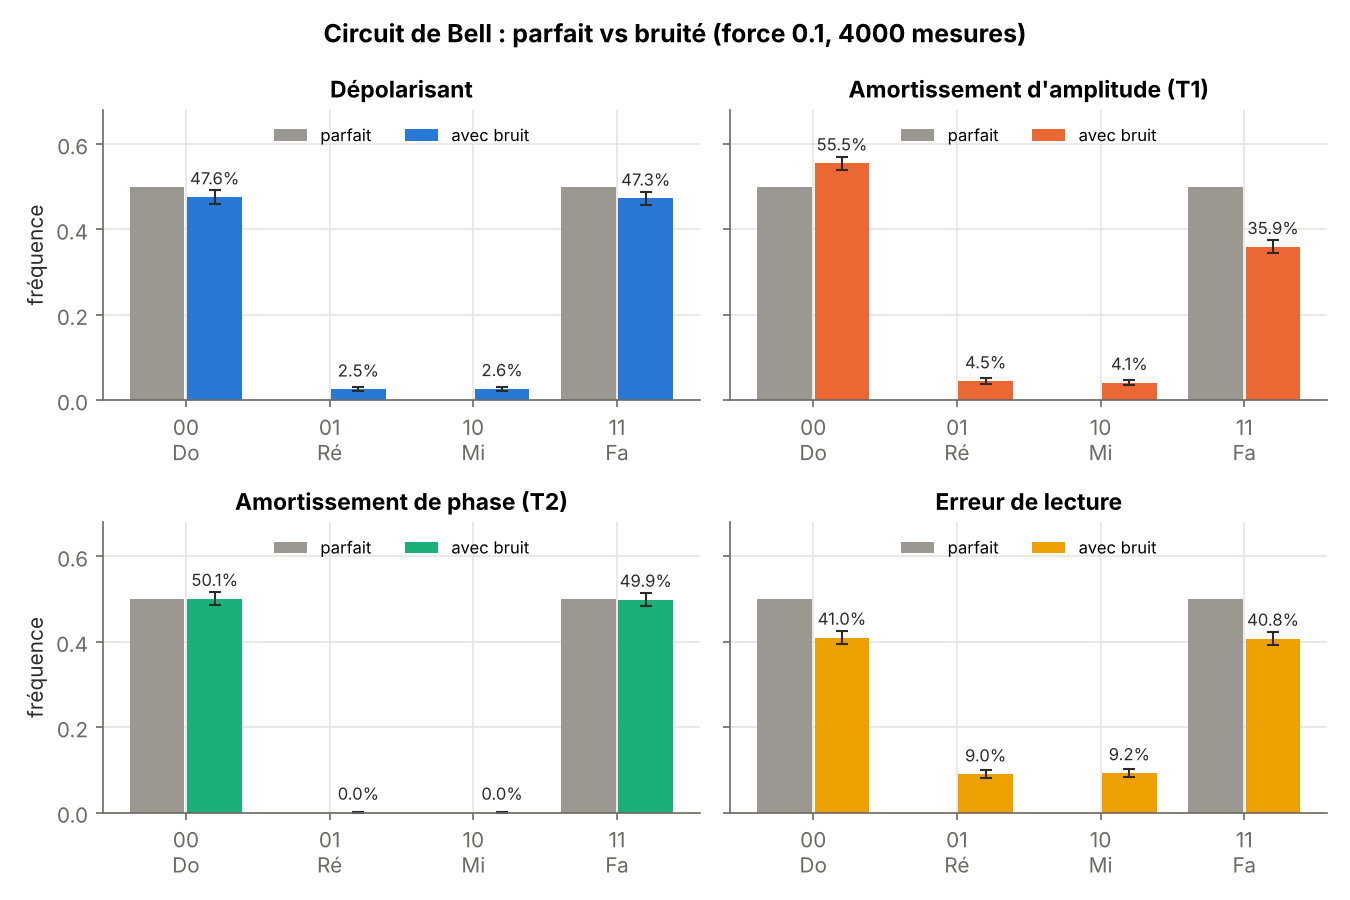

**Figure 2 : plus le bruit est fort, plus on s'éloigne du cas parfait**

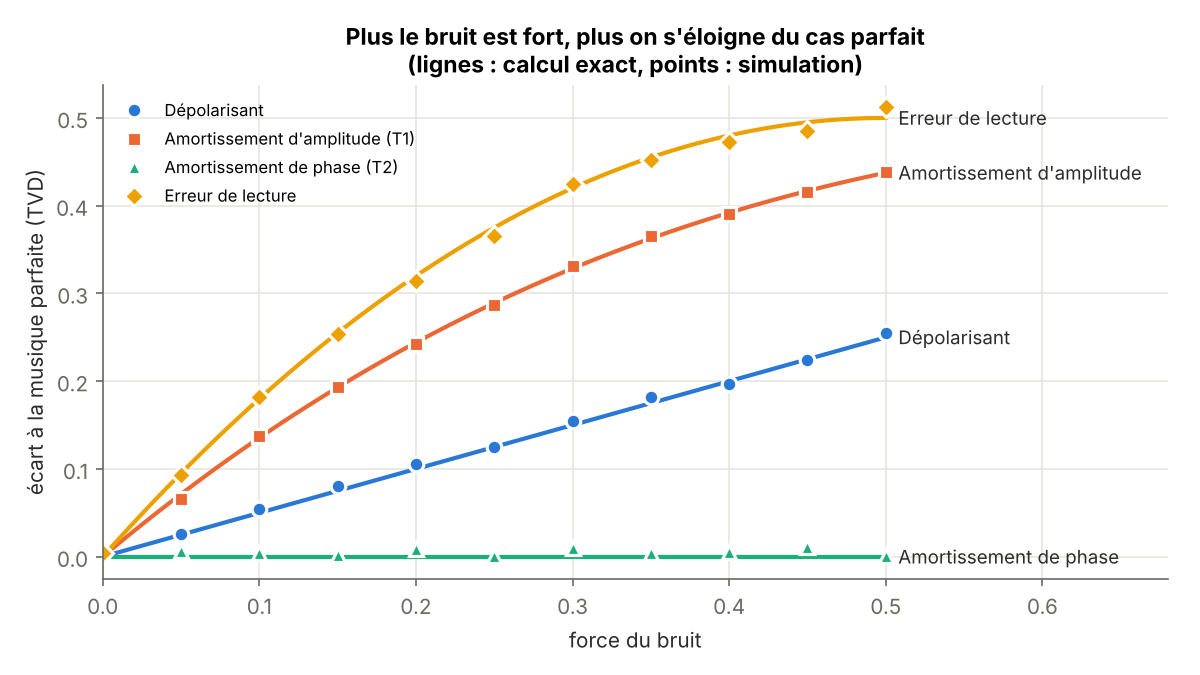

**Figure 3 : état ou lecture ? Le test de la profondeur**

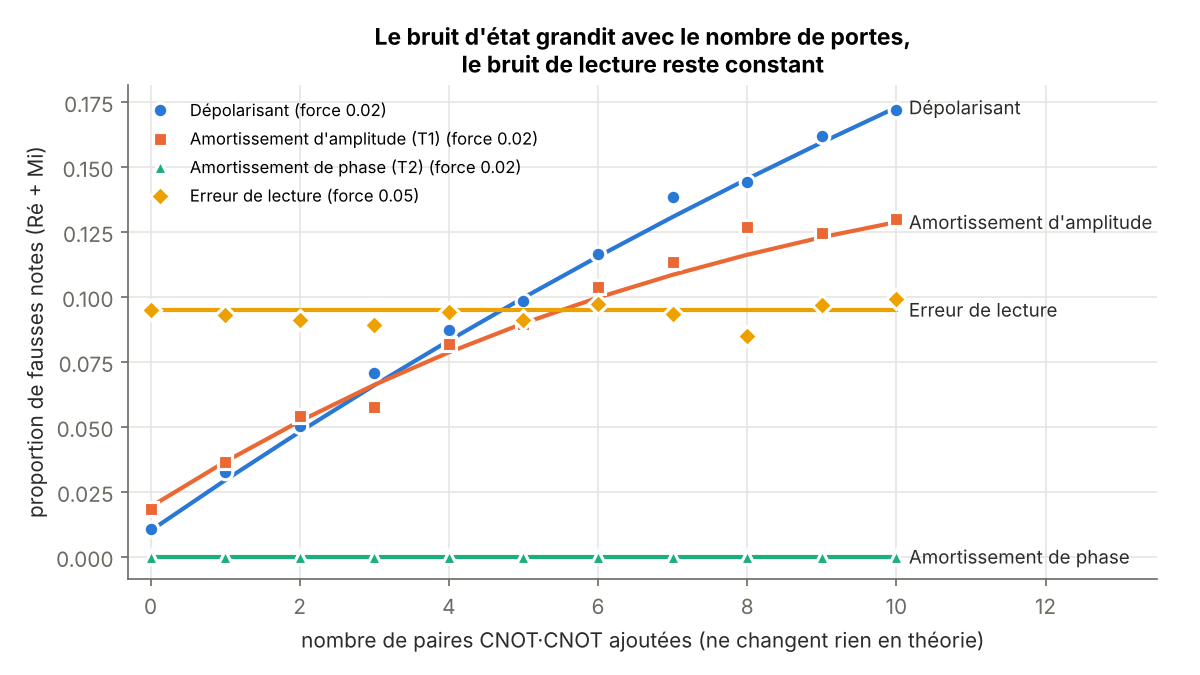

**Figure 4 : état ou lecture ? La correction de lecture**

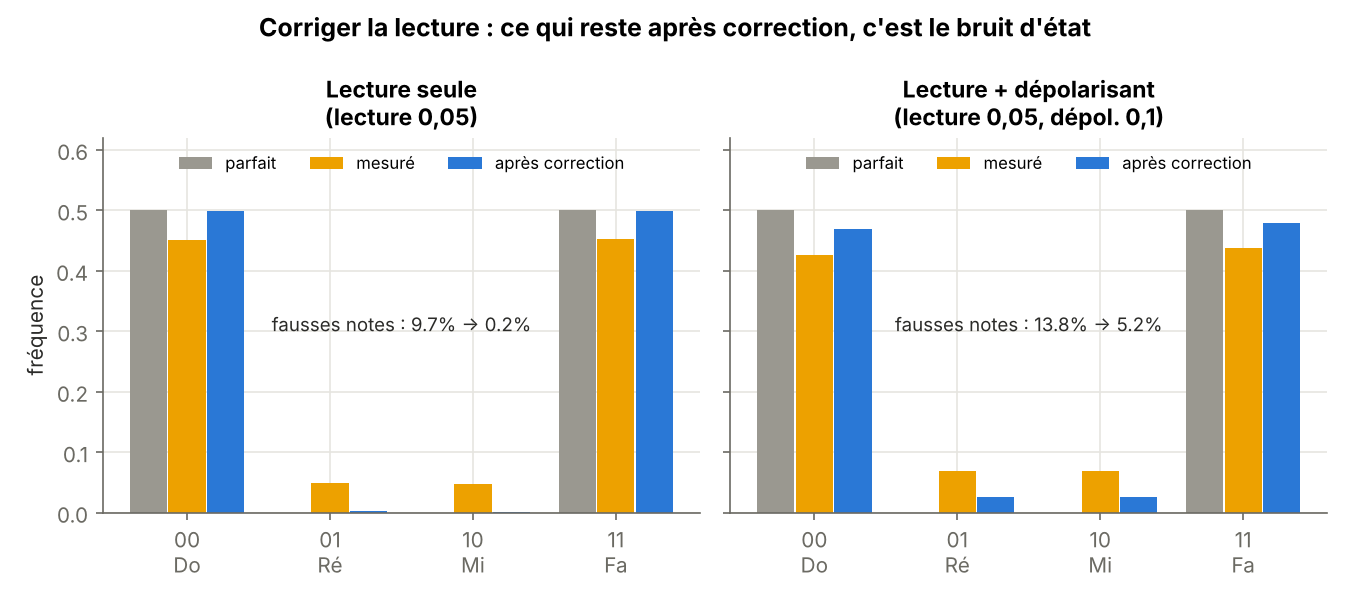

**Figure 5 : à partir de quand le comportement devient classique**

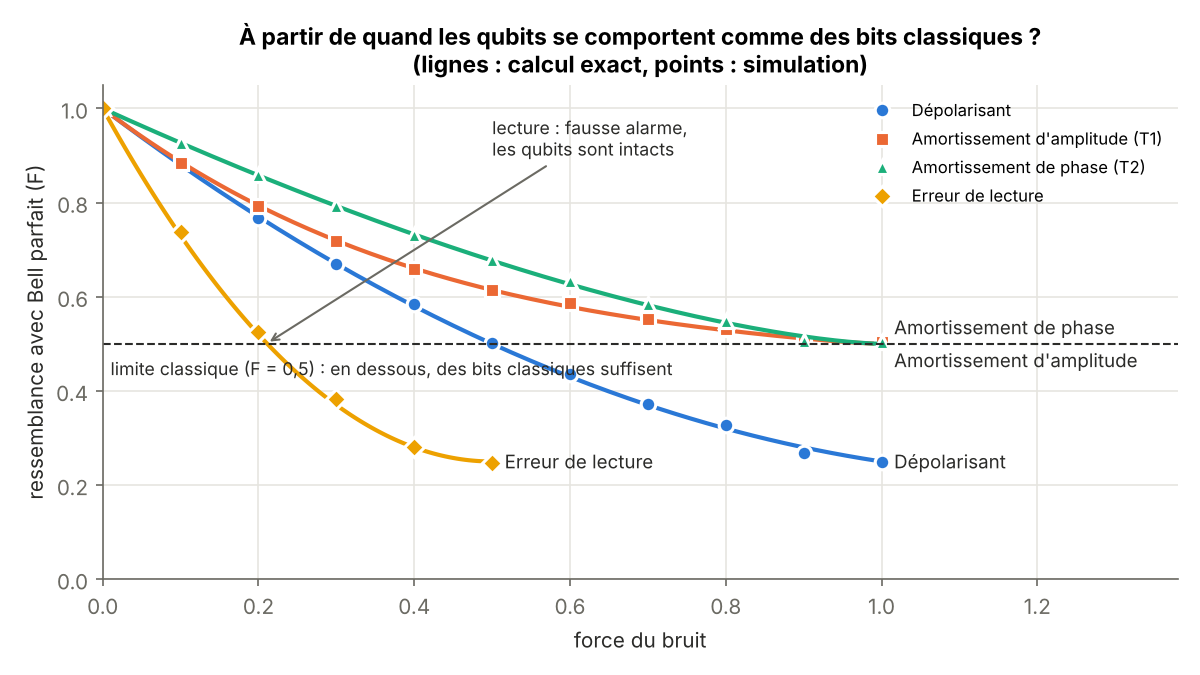

In [9]:
import subprocess, os
from IPython.display import Image, display, Markdown

racine = pathlib.Path.cwd().parent
env = dict(os.environ, PYTHONPATH=str(racine / "src"))
subprocess.run([sys.executable, str(racine / "experiments" / "noise_experiments.py")],
               cwd=racine, env=env, check=True, capture_output=True)

titres = {
    "noise_1_distributions.png": "Figure 1 : Bell parfait vs bruité, pour chaque bruit",
    "noise_2_sweep.png": "Figure 2 : plus le bruit est fort, plus on s'éloigne du cas parfait",
    "noise_3_depth.png": "Figure 3 : état ou lecture ? Le test de la profondeur",
    "noise_4_mitigation.png": "Figure 4 : état ou lecture ? La correction de lecture",
    "noise_5_quantum_classical.png": "Figure 5 : à partir de quand le comportement devient classique",
}
for fichier, titre in titres.items():
    display(Markdown(f"**{titre}**"))
    display(Image(filename=str(racine / "figures" / fichier), width=750))